In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import ttest_ind
from sklearn.linear_model import LinearRegression

from ics26_experiments import ICS26_DIR

In [ ]:
subdirs = [d.name for d in ICS26_DIR.iterdir() if d.is_dir()]
print(subdirs)

['adaptive_clustering_global_vs_local', 'adaptive_clustering_global_vs_n_init_clusters', 'adaptive_clustering_global_local_vs_min_pts_per_cluster', 'rosenbrock_convergence', 'shrinkage_analysis', 'ellipsoidal_knn_containment']


In [ ]:
# Publication-Quality Plot Settings
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.family": "serif",
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "figure.figsize": (6.5, 4.5),
        "figure.dpi": 100,
        "savefig.dpi": 300,
        "lines.linewidth": 1.5,
        "lines.markersize": 5,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.axisbelow": True,
    }
)
PALETTE = "deep"
COLORS = sns.color_palette(PALETTE)

# Adaptive Clustering: Global vs Local Error Type

In [ ]:
adaptive_clustering_dir = ICS26_DIR / "adaptive_clustering_global_vs_local"
csv_path = adaptive_clustering_dir / "summary.csv"

df_ac_gl = pd.read_csv(csv_path)

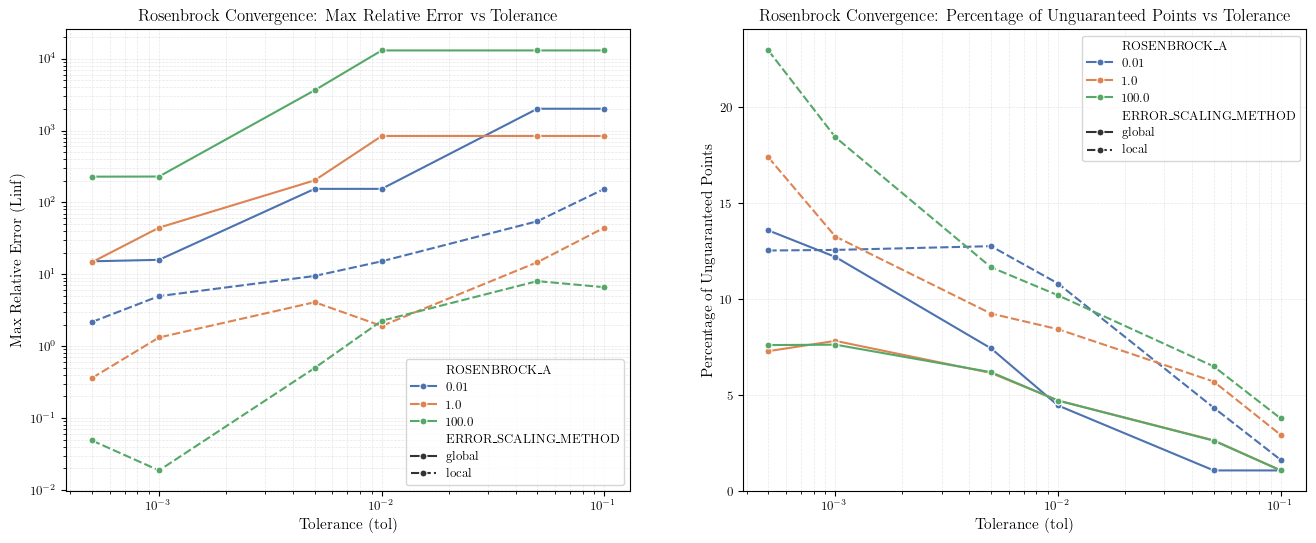

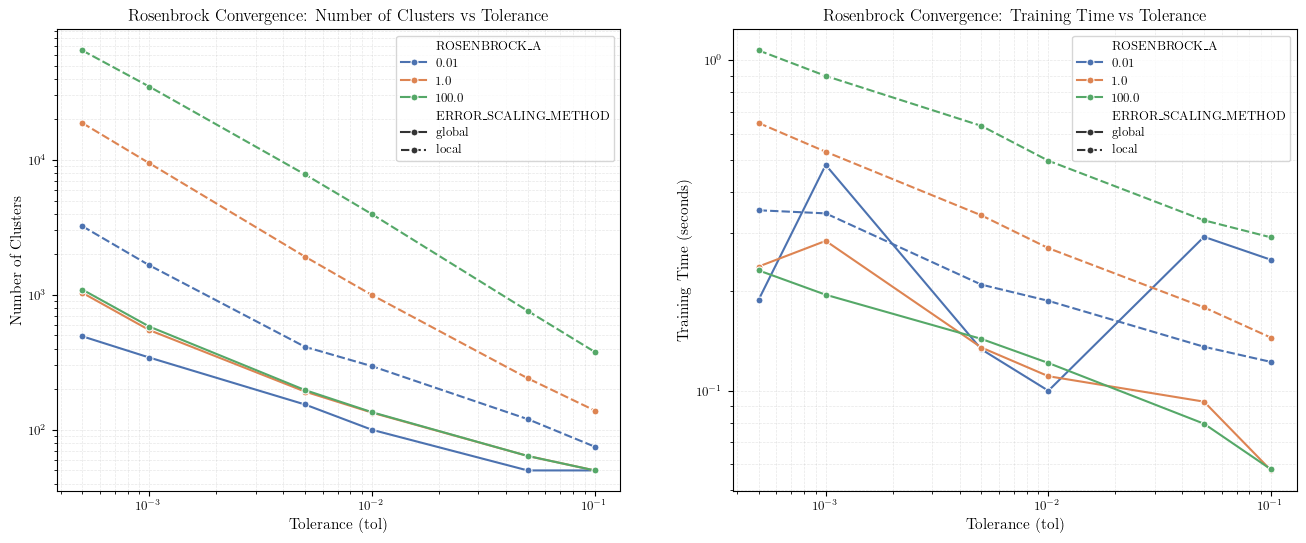

In [ ]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_ac_gl,
    x="tol",
    y="max_rel_error_linf",
    style="ERROR_SCALING_METHOD",
    hue="ROSENBROCK_A",
    marker="o",
    palette=PALETTE,
)

plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Max Relative Error (Linf)")
plt.title("Rosenbrock Convergence: Max Relative Error vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_ac_gl,
    x="tol",
    y="perct_ungauranteed",
    style="ERROR_SCALING_METHOD",
    hue="ROSENBROCK_A",
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Percentage of Unguaranteed Points")
plt.title("Rosenbrock Convergence: Percentage of Unguaranteed Points vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_ac_gl,
    x="tol",
    y="n_clusters",
    style="ERROR_SCALING_METHOD",
    hue="ROSENBROCK_A",
    marker="o",
    palette=PALETTE,
)

plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Number of Clusters")
plt.title("Rosenbrock Convergence: Number of Clusters vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_ac_gl,
    x="tol",
    y="train_time_sec",
    style="ERROR_SCALING_METHOD",
    hue="ROSENBROCK_A",
    marker="o",
    palette=PALETTE,
)
plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Training Time (seconds)")
plt.title("Rosenbrock Convergence: Training Time vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

### Comparing Means of max_rel_error_linf for global vs local (varying Rosenbrock A)

In [ ]:
err_col = "max_rel_error_linf"
global_array = df_ac_gl[df_ac_gl["ERROR_SCALING_METHOD"] == "global"][err_col]
local_array = df_ac_gl[df_ac_gl["ERROR_SCALING_METHOD"] == "local"][err_col]

t_stat, p_val = ttest_ind(global_array, local_array)
print(f"T-stat: {t_stat:.1e}, p-val: {p_val*100:.1f}%")

T-stat: 2.5e+00, p-val: 1.9%


### Comparing Means of n_clusters for global vs local (varying Rosenbrock A)

In [ ]:
cluster_col = "n_clusters"
global_array = df_ac_gl[df_ac_gl["ERROR_SCALING_METHOD"] == "global"][cluster_col]
local_array = df_ac_gl[df_ac_gl["ERROR_SCALING_METHOD"] == "local"][cluster_col]

t_stat, p_val = ttest_ind(global_array, local_array)
print(f"T-stat: {t_stat:.1e}, p-val: {p_val*100:.1f}%")

T-stat: -2.0e+00, p-val: 4.8%


# Adaptive Clustering: Variation of Num of Initial CLusters

In [ ]:
ac_n_init_dir = ICS26_DIR / "adaptive_clustering_global_vs_n_init_clusters"
csv_path = ac_n_init_dir / "summary.csv"

df_ac_ninit = pd.read_csv(csv_path)
df_ac_ninit["ROSENBROCK_DIM_A_ERR"] = (
    df_ac_ninit["dim"].astype(str)
    + "D_"
    + df_ac_ninit["ROSENBROCK_A"].astype(str)
    + "A_"
    + df_ac_ninit["ERROR_SCALING_METHOD"].astype(str)
)

Text(0.5, 1.0, 'Correlation Heatmap: Varying N_INIT_CLUSTERS')

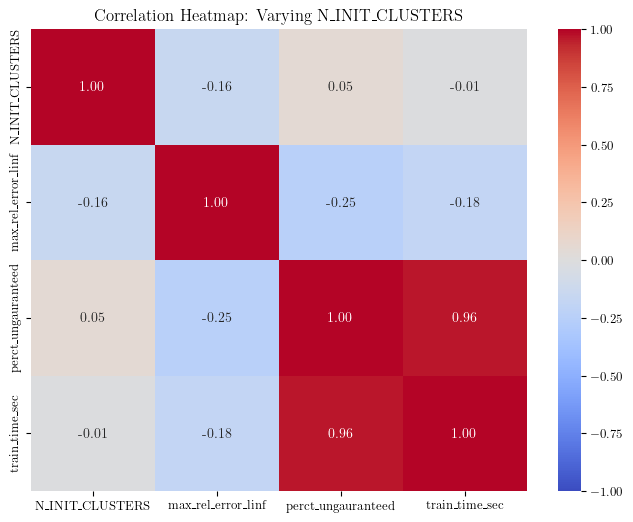

In [ ]:
cols = ["N_INIT_CLUSTERS", "max_rel_error_linf", "perct_ungauranteed", "train_time_sec"]
corr_df = df_ac_ninit[cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr_df, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap: Varying N_INIT_CLUSTERS")

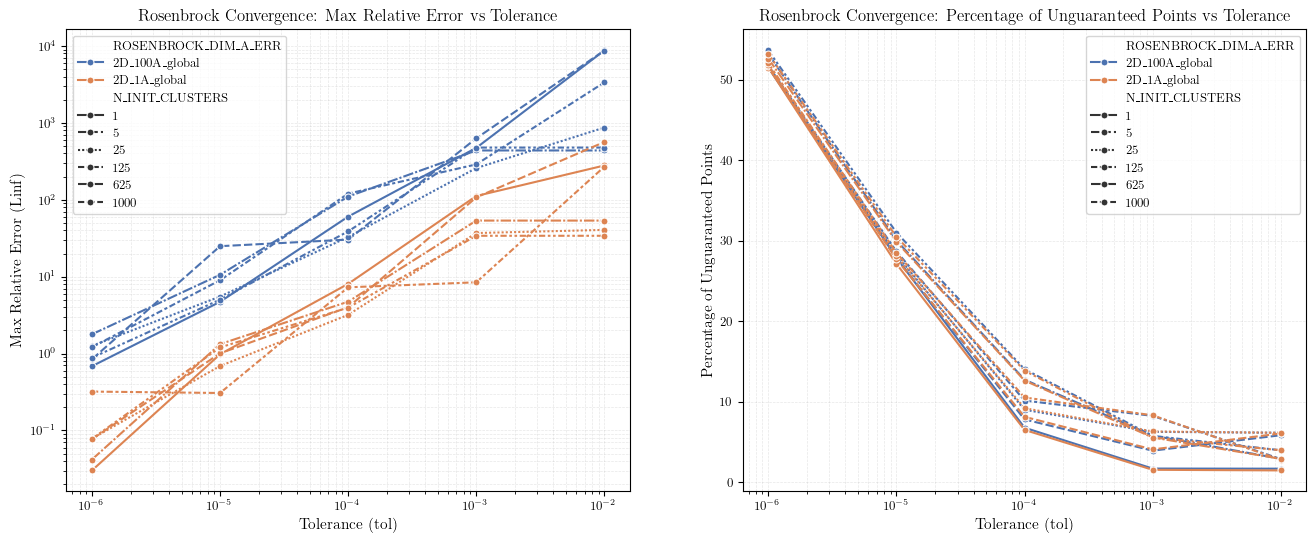

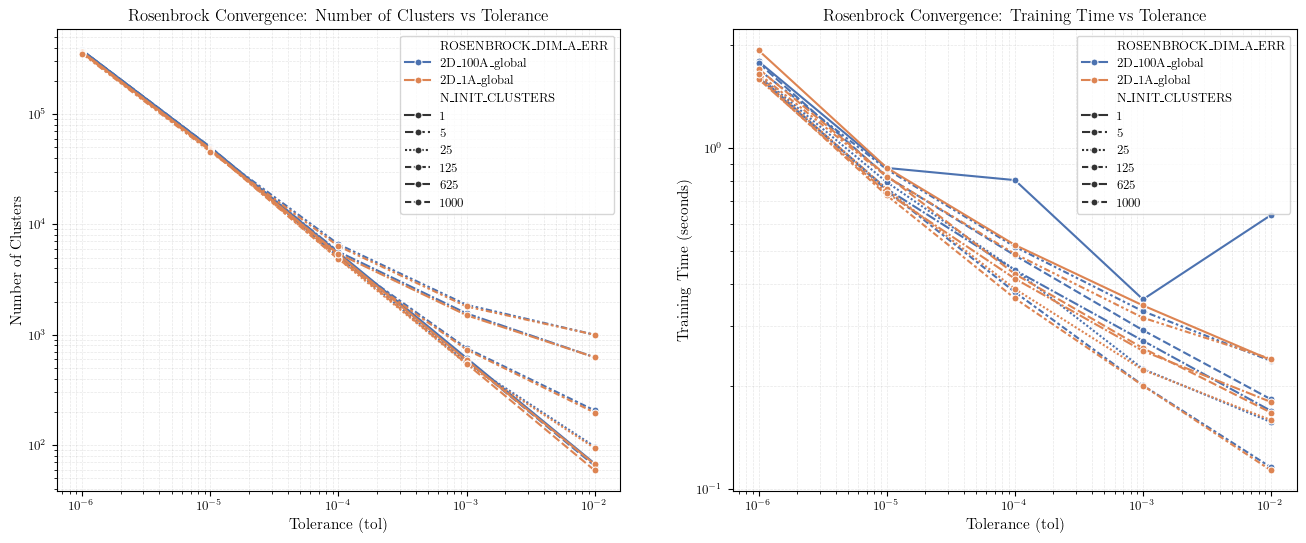

In [ ]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_ac_ninit,
    x="tol",
    y="max_rel_error_linf",
    style="N_INIT_CLUSTERS",
    hue="ROSENBROCK_DIM_A_ERR",
    marker="o",
    palette=PALETTE,
)

plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Max Relative Error (Linf)")
plt.title("Rosenbrock Convergence: Max Relative Error vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_ac_ninit,
    x="tol",
    y="perct_ungauranteed",
    style="N_INIT_CLUSTERS",
    hue="ROSENBROCK_DIM_A_ERR",
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Percentage of Unguaranteed Points")
plt.title("Rosenbrock Convergence: Percentage of Unguaranteed Points vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_ac_ninit,
    x="tol",
    y="n_clusters",
    style="N_INIT_CLUSTERS",
    hue="ROSENBROCK_DIM_A_ERR",
    marker="o",
    palette=PALETTE,
)

plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Number of Clusters")
plt.title("Rosenbrock Convergence: Number of Clusters vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_ac_ninit,
    x="tol",
    y="train_time_sec",
    style="N_INIT_CLUSTERS",
    hue="ROSENBROCK_DIM_A_ERR",
    marker="o",
    palette=PALETTE,
)
plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Training Time (seconds)")
plt.title("Rosenbrock Convergence: Training Time vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

# Adaptive Clustering: Variation of Min Points per Cluster

In [ ]:
ac_mppc = ICS26_DIR / "adaptive_clustering_global_local_vs_min_pts_per_cluster"
csv_path = ac_mppc / "summary.csv"

df_ac_mppc = pd.read_csv(csv_path)
df_ac_mppc["ROSENBROCK_DIM_A_ERR"] = (
    df_ac_mppc["dim"].astype(str)
    + "D_"
    + df_ac_mppc["ROSENBROCK_A"].astype(str)
    + "A_"
    + df_ac_mppc["ERROR_SCALING_METHOD"].astype(str)
)

Text(0.5, 1.0, 'Correlation Heatmap: Varying N_MIN_PER_CLUSTER')

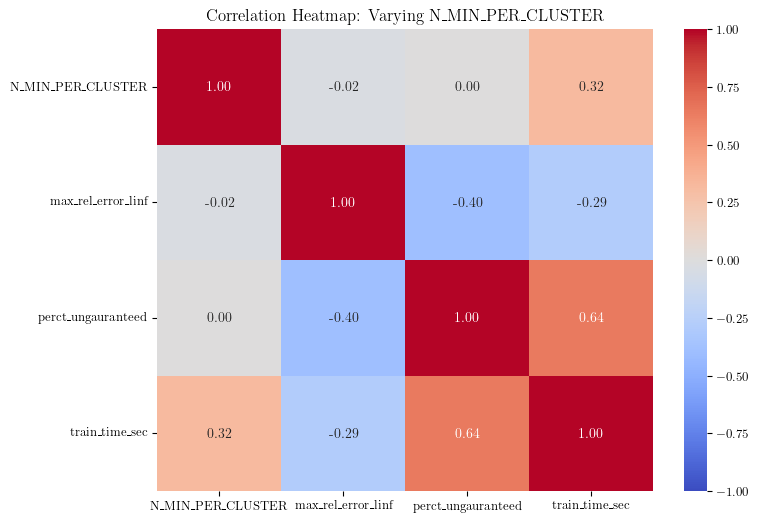

In [ ]:
cols = [
    "N_MIN_PER_CLUSTER",
    "max_rel_error_linf",
    "perct_ungauranteed",
    "train_time_sec",
]
corr_df = df_ac_mppc[cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr_df, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap: Varying N_MIN_PER_CLUSTER")

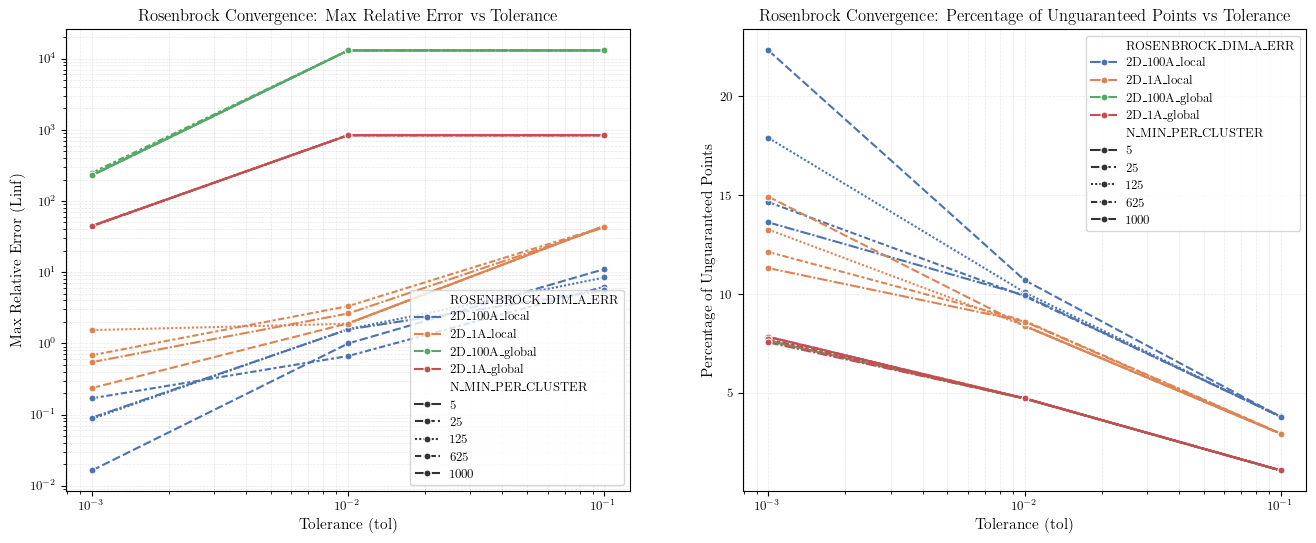

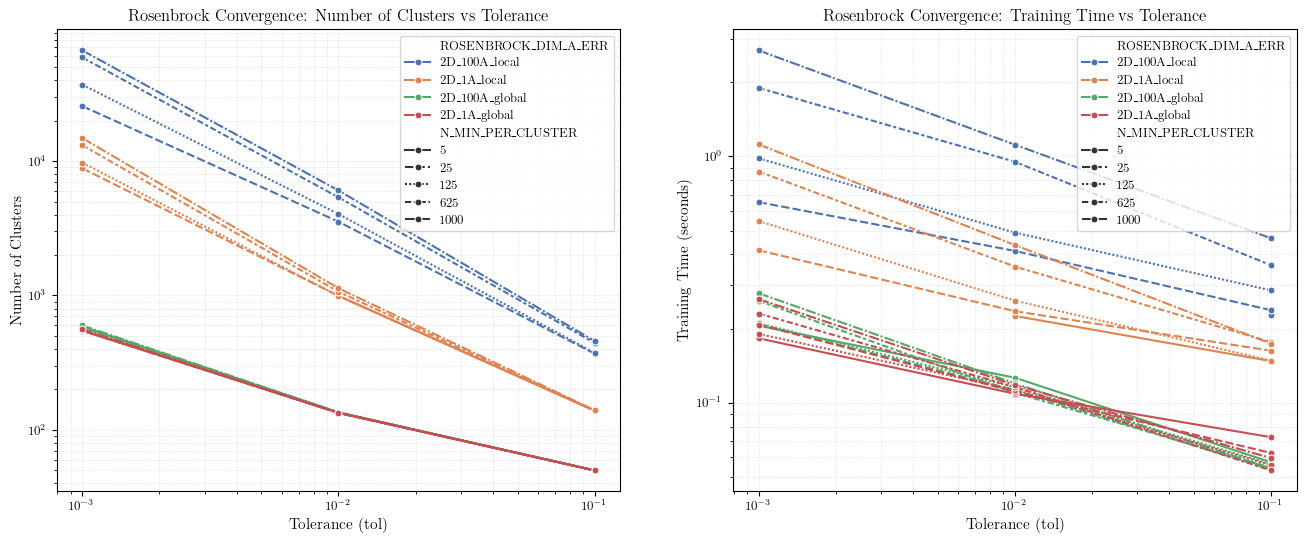

In [ ]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_ac_mppc,
    x="tol",
    y="max_rel_error_linf",
    hue="ROSENBROCK_DIM_A_ERR",
    style="N_MIN_PER_CLUSTER",
    marker="o",
    palette=PALETTE,
)

plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Max Relative Error (Linf)")
plt.title("Rosenbrock Convergence: Max Relative Error vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_ac_mppc,
    x="tol",
    y="perct_ungauranteed",
    hue="ROSENBROCK_DIM_A_ERR",
    style="N_MIN_PER_CLUSTER",
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Percentage of Unguaranteed Points")
plt.title("Rosenbrock Convergence: Percentage of Unguaranteed Points vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_ac_mppc,
    x="tol",
    y="n_clusters",
    hue="ROSENBROCK_DIM_A_ERR",
    style="N_MIN_PER_CLUSTER",
    marker="o",
    palette=PALETTE,
)

plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Number of Clusters")
plt.title("Rosenbrock Convergence: Number of Clusters vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_ac_mppc,
    x="tol",
    y="train_time_sec",
    hue="ROSENBROCK_DIM_A_ERR",
    style="N_MIN_PER_CLUSTER",
    marker="o",
    palette=PALETTE,
)
plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Training Time (seconds)")
plt.title("Rosenbrock Convergence: Training Time vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

# Ellipsoidal KNN Containment EDAA

In [ ]:
ellipsoidal_dir = ICS26_DIR / "ellipsoidal_knn_containment"
csv_path = ellipsoidal_dir / "summary.csv"

df_ellipsoidal_knn = pd.read_csv(csv_path)

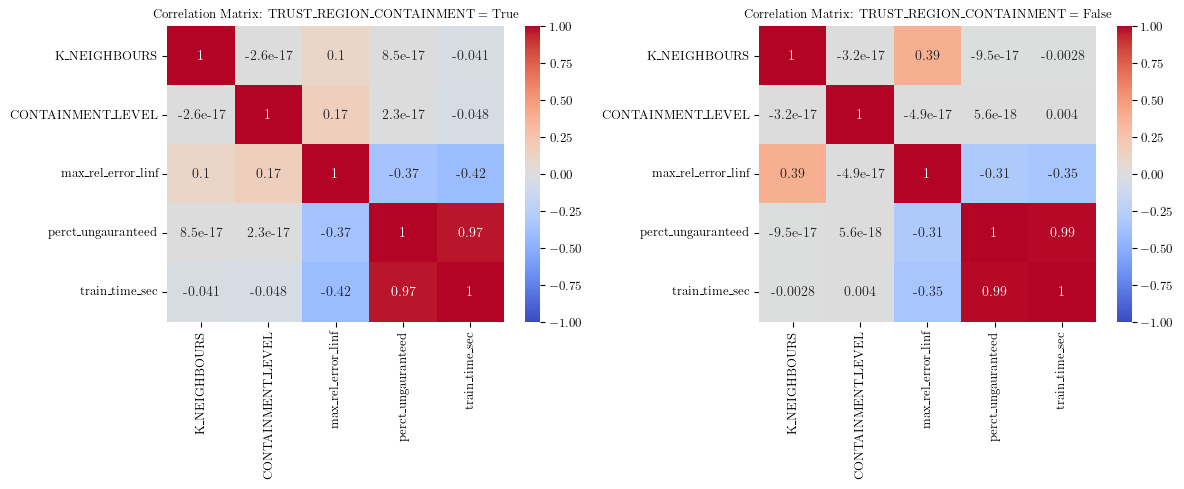

In [ ]:
cols = [
    "K_NEIGHBOURS",
    "CONTAINMENT_LEVEL",
    "max_rel_error_linf",
    "perct_ungauranteed",
    "train_time_sec",
]
trc_col = "TRUST_REGION_CONTAINMENT"
corr_df_constrained = df_ellipsoidal_knn[df_ellipsoidal_knn[trc_col] == True][cols]
corr_df_unconstrained = df_ellipsoidal_knn[df_ellipsoidal_knn[trc_col] == False][cols]

corr_constrained = corr_df_constrained.corr()
corr_unconstrained = corr_df_unconstrained.corr()

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.heatmap(corr_constrained, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title(f"Correlation Matrix: {trc_col} = True", fontsize=9)
plt.subplot(1, 2, 2)
sns.heatmap(corr_unconstrained, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title(f"Correlation Matrix: {trc_col} = False", fontsize=9)
plt.tight_layout()

### Testing means of max_rel_error_linf for constrained vs unconstrained (CL=1)

In [ ]:
conds = df_ellipsoidal_knn["CONTAINMENT_LEVEL"] == 1
max_rel_error_linf_constrained = df_ellipsoidal_knn[
    conds & (df_ellipsoidal_knn[trc_col] == True)
][err_col]
max_rel_error_linf_unconstrained = df_ellipsoidal_knn[
    conds & (df_ellipsoidal_knn[trc_col] == False)
][err_col]

t_stat, p_val = ttest_ind(
    max_rel_error_linf_constrained, max_rel_error_linf_unconstrained
)
mean_1 = max_rel_error_linf_constrained.mean()
mean_2 = max_rel_error_linf_unconstrained.mean()
print(f"Means: {mean_1:.2f} (constrained, CL=1) vs {mean_2:.2f} (unconstrained, CL=1)")
print(f"T-statistic: {t_stat}, P-value: {p_val*100:.2f}%")  # type: ignore

Means: 2666.03 (constrained, CL=1) vs 13363.57 (unconstrained, CL=1)
T-statistic: -1.7458872953790394, P-value: 8.61%


### Testing means of max_rel_error_linf for CL = 1 vs CL = 2 (constrained)

In [ ]:
err_col = "max_rel_error_linf"
conds = df_ellipsoidal_knn[trc_col] == True
max_rel_error_linf_cl1 = df_ellipsoidal_knn[
    conds & (df_ellipsoidal_knn["CONTAINMENT_LEVEL"] == 1)
][err_col]
max_rel_error_linf_cl2 = df_ellipsoidal_knn[
    conds & (df_ellipsoidal_knn["CONTAINMENT_LEVEL"] == 2)
][err_col]

t_stat, p_val = ttest_ind(max_rel_error_linf_cl1, max_rel_error_linf_cl2)
mean_1 = max_rel_error_linf_cl1.mean()
mean_2 = max_rel_error_linf_cl2.mean()
print(f"Means: {mean_1:.2f} (constrained, CL=1) vs {mean_2:.2f} (constrained, CL=2)")
print(f"T-statistic: {t_stat}, P-value: {p_val*100:.2f}%")  # type: ignore

Means: 2666.03 (constrained, CL=1) vs 4895.50 (constrained, CL=2)
T-statistic: -1.2234529400384828, P-value: 22.61%


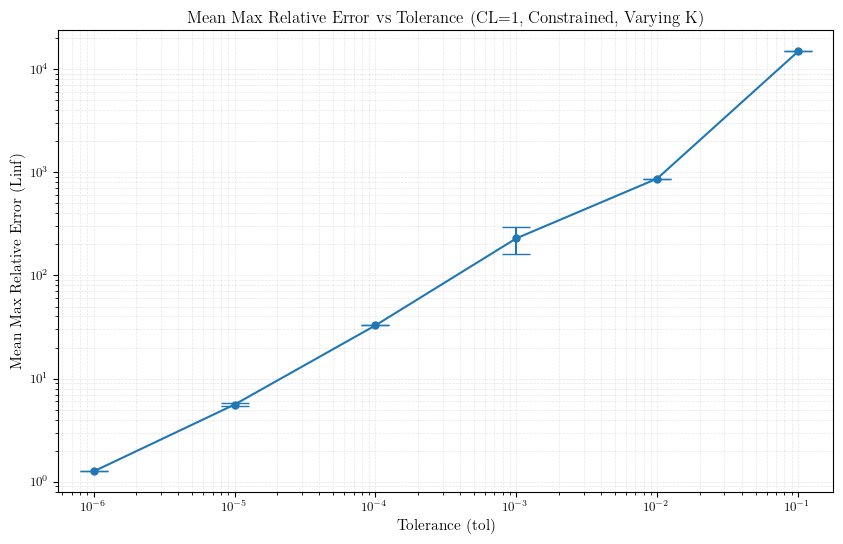

In [ ]:
cond = (df_ellipsoidal_knn[trc_col] == True) & (
    df_ellipsoidal_knn["CONTAINMENT_LEVEL"] == 1
)

# Plot histograms of max_rel_error_linf for different tols with error bars
tols = sorted(df_ellipsoidal_knn[cond]["tol"].unique())
plt.figure(figsize=(10, 6))
data = []
for tol in tols:
    subset = df_ellipsoidal_knn[cond & (df_ellipsoidal_knn["tol"] == tol)][
        "max_rel_error_linf"
    ]
    _mu, _std = subset.mean(), subset.std()
    data.append((tol, _mu, _std))

tols, mus, stds = zip(*data)
plt.errorbar(tols, mus, yerr=stds, fmt="o-", capsize=10)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Mean Max Relative Error (Linf)")
plt.title("Mean Max Relative Error vs Tolerance (CL=1, Constrained, Varying K)")
plt.grid(True, which="both", ls="--", lw=0.5)

## Insights
- The mean maximum relative error (L-infinity) is lower when `TRUST_REGION_CONTAINMENT` is enabled, as compared to when it is disabled (p-value ~ 0.06).
- When `TRUST_REGION_CONTAINMENT` is enabled, the mean maximum relative error (L-infinity) is lower for containment level 1 compared to containment level 2 (p-value ~ 0.03).
- With `TRUST_REGION_CONTAINMENT` enabled, and containment level set to 1, the `kNN` value does not significantly affect the maximum relative error (L-infinity)

# Rosenbrock Convergence EDA 

In [ ]:
rosenbrock_dir = ICS26_DIR / "rosenbrock_convergence"
csv_path = rosenbrock_dir / "summary.csv"

df_rb = pd.read_csv(csv_path)

df_rb["rosenbrock_DIM_A"] = (
    df_rb["dim"].astype(str) + "D_" + df_rb["ROSENBROCK_A"].astype(str) + "A"
)

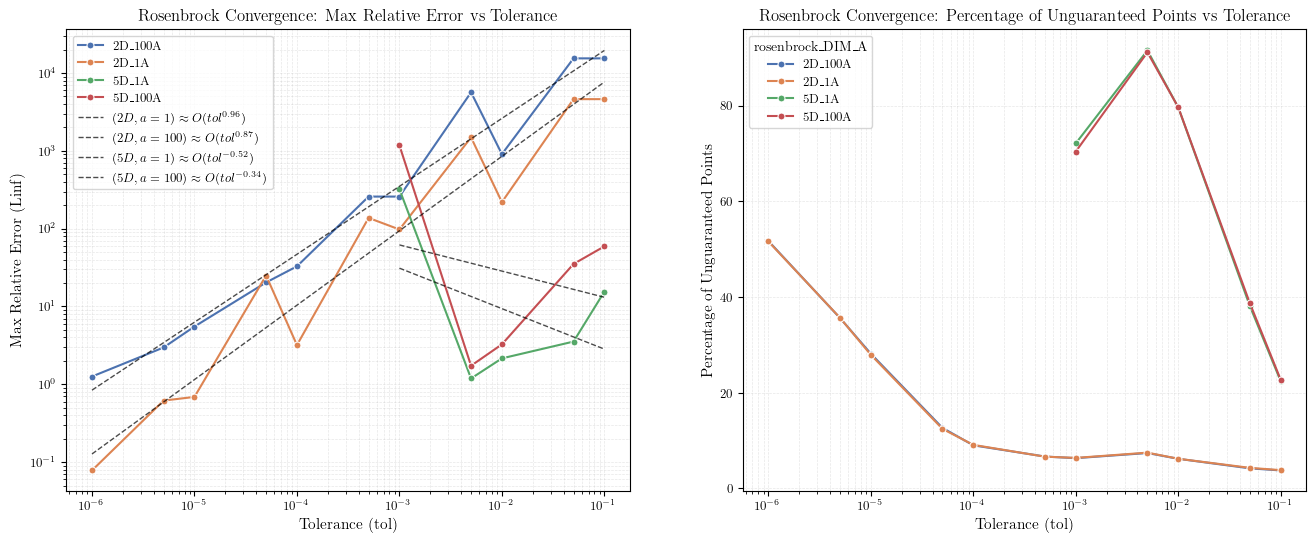

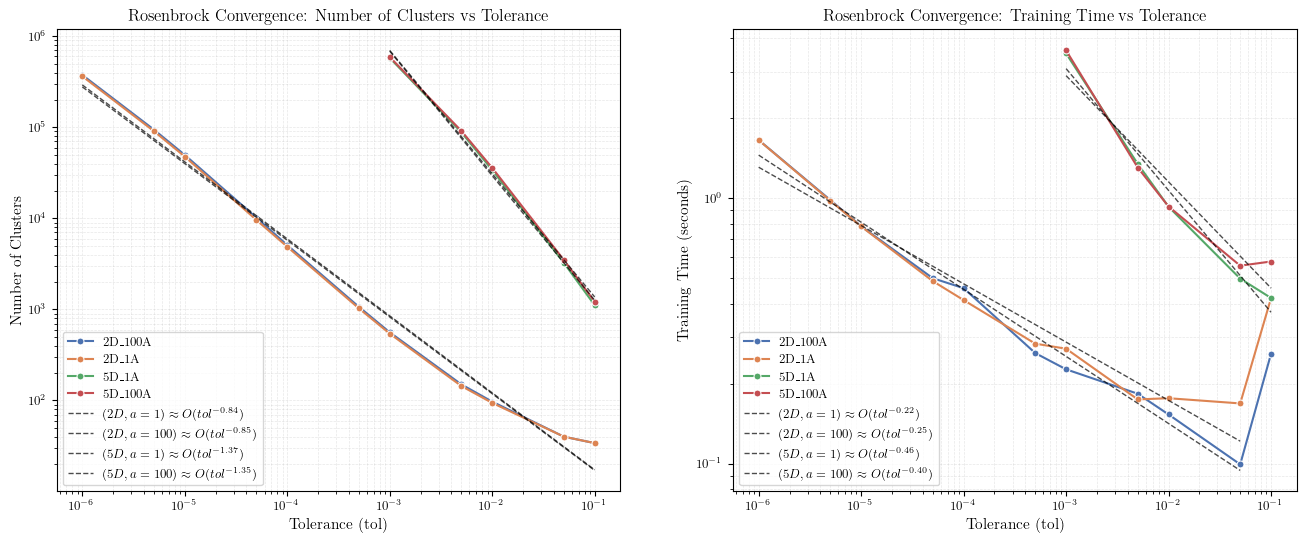

In [ ]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_rb,
    x="tol",
    y="max_rel_error_linf",
    hue="rosenbrock_DIM_A",
    marker="o",
    palette=PALETTE,
)

# Fit a line to each series to estimate convergence rate
for (dim, a_val), group in df_rb.groupby(["dim", "ROSENBROCK_A"]):
    # Skip nan or inf values
    group = group.where(~group.isin([np.inf, -np.inf]), np.nan).dropna(
        subset=["max_rel_error_linf"]
    )
    if len(group) < 4:
        continue
    X = np.log(group["tol"]).values.reshape(-1, 1)
    y = np.log(group["max_rel_error_linf"]).values
    model = LinearRegression()
    model.fit(X, y)

    # Plot the fitted line
    x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
    y_fit = model.predict(x_fit)
    plt.plot(
        np.exp(x_fit),
        np.exp(y_fit),
        linestyle="--",
        color="k",
        lw=1,
        alpha=0.7,
        label=rf"$({dim}D, a={a_val}) \approx O(tol^{{{model.coef_[0]:.2f}}})$",
    )

plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Max Relative Error (Linf)")
plt.title("Rosenbrock Convergence: Max Relative Error vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_rb,
    x="tol",
    y="perct_ungauranteed",
    hue="rosenbrock_DIM_A",
    marker="o",
    palette=PALETTE,
)
plt.xscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Percentage of Unguaranteed Points")
plt.title("Rosenbrock Convergence: Percentage of Unguaranteed Points vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)


plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_rb,
    x="tol",
    y="n_clusters",
    hue="rosenbrock_DIM_A",
    marker="o",
    palette=PALETTE,
)
# Fit a line to each series to estimate cluster growth rate
for (dim, a_val), group in df_rb.groupby(["dim", "ROSENBROCK_A"]):
    # Skip nan or inf values
    group = group.where(~group.isin([np.inf, -np.inf]), np.nan).dropna(
        subset=["n_clusters"]
    )
    if len(group) < 3:
        continue
    X = np.log(group["tol"]).values.reshape(-1, 1)
    y = np.log(group["n_clusters"]).values
    model = LinearRegression()
    model.fit(X, y)
    # Plot the fitted line
    x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
    y_fit = model.predict(x_fit)
    plt.plot(
        np.exp(x_fit),
        np.exp(y_fit),
        linestyle="--",
        color="k",
        lw=1,
        alpha=0.7,
        label=rf"$({dim}D, a={a_val}) \approx O(tol^{{{model.coef_[0]:.2f}}})$",
    )

plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Number of Clusters")
plt.title("Rosenbrock Convergence: Number of Clusters vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_rb,
    x="tol",
    y="train_time_sec",
    hue="rosenbrock_DIM_A",
    marker="o",
    palette=PALETTE,
)
# Fit a line to each series to estimate training time growth rate
for (dim, a_val), group in df_rb.groupby(["dim", "ROSENBROCK_A"]):
    # Skip nan or inf values
    group = group.where(~group.isin([np.inf, -np.inf]), np.nan).dropna(
        subset=["train_time_sec"]
    )
    if len(group) < 3:
        continue
    X = np.log(group["tol"]).values.reshape(-1, 1)
    y = np.log(group["train_time_sec"]).values

    # if dim == 2 ignore first data point to avoid skewing
    if dim == 2:
        X = X[1:]
        y = y[1:]
    model = LinearRegression()
    model.fit(X, y)
    # Plot the fitted line
    x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
    y_fit = model.predict(x_fit)
    plt.plot(
        np.exp(x_fit),
        np.exp(y_fit),
        linestyle="--",
        color="k",
        lw=1,
        alpha=0.7,
        label=rf"$({dim}D, a={a_val}) \approx O(tol^{{{model.coef_[0]:.2f}}})$",
    )
plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Training Time (seconds)")
plt.title("Rosenbrock Convergence: Training Time vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)